# 01 — Clustering: K-means, Hierarchical, DBSCAN

**Overview:** fit K-means, hierarchical clustering (with a dendrogram), and DBSCAN on the same
data, then show a case (non-convex clusters) where K-means visibly fails and DBSCAN succeeds.

**Required libraries:** `numpy`, `matplotlib`, `scikit-learn`, `scipy`.

Connects to: `08_classification` (same sklearn fit/predict idiom, now with no labels). Leads to:
`02_dimensionality_reduction.ipynb`.

### Abbreviations used in this notebook

| Term | Full form | What it is |
|---|---|---|
| **DBSCAN** | Density-Based Spatial Clustering of Applications with Noise | Clusters dense regions and labels sparse points as noise; no need to set k. |
| **ARI** | Adjusted Rand Index | Agreement between clusters and true labels, corrected for chance (1 = perfect, ~0 = random). |
| **PCA** | Principal Component Analysis | Linear dimensionality reduction: projects data onto orthogonal directions of maximum variance. |
| **t-SNE** | t-distributed Stochastic Neighbor Embedding | Non-linear 2D/3D embedding that preserves local neighbourhoods; for visualisation only. |

## 0. Environment

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.datasets import make_blobs, make_moons
from sklearn.preprocessing import StandardScaler
from scipy.cluster.hierarchy import dendrogram, linkage

rng = np.random.default_rng(42)


## 1. K-means on well-separated, roughly spherical blobs (the easy case)

cluster centers:
 [[-2.60842567  9.03771305]
 [-6.88302287 -6.96320924]
 [ 4.72565847  2.00310936]]


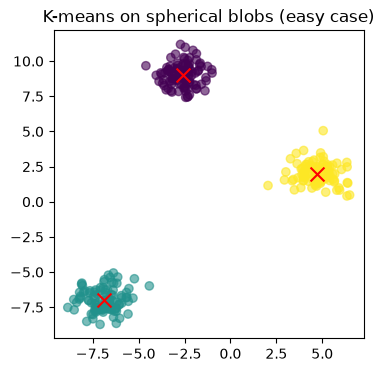

agreement with true cluster labels (Adjusted Rand Index): 1.000


In [2]:
X_blobs, y_true_blobs = make_blobs(n_samples=300, centers=3, cluster_std=0.8, random_state=42)

kmeans = KMeans(n_clusters=3, random_state=42, n_init=10).fit(X_blobs)
print("cluster centers:\n", kmeans.cluster_centers_)

fig, ax = plt.subplots(figsize=(4, 4))
ax.scatter(X_blobs[:, 0], X_blobs[:, 1], c=kmeans.labels_, cmap="viridis", alpha=0.6)
ax.scatter(kmeans.cluster_centers_[:, 0], kmeans.cluster_centers_[:, 1], c="red", marker="x", s=100)
ax.set_title("K-means on spherical blobs (easy case)")
plt.show()

from sklearn.metrics import adjusted_rand_score
ari = adjusted_rand_score(y_true_blobs, kmeans.labels_)
print(f"agreement with true cluster labels (Adjusted Rand Index): {ari:.3f}")
assert ari > 0.8


## 2. Choosing k: the elbow method

💡 **Intuition:** inertia (within-cluster sum of squares) always decreases as `k` grows — look
for the "elbow" where adding more clusters stops helping much.

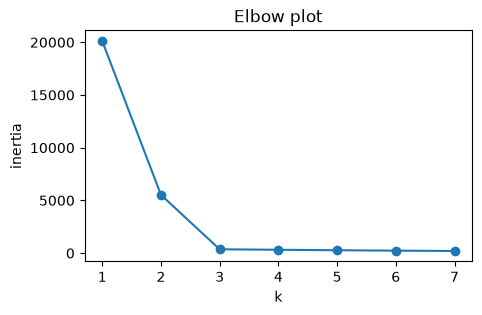

inertias: [20120.5, 5526.5, 362.8, 318.1, 273.4, 233.6, 201.0]
The elbow should appear around k=3, matching the true number of blobs.


In [3]:
inertias = []
k_range = range(1, 8)
for k in k_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10).fit(X_blobs)
    inertias.append(km.inertia_)

fig, ax = plt.subplots(figsize=(5, 3))
ax.plot(list(k_range), inertias, marker="o")
ax.set_xlabel("k"); ax.set_ylabel("inertia"); ax.set_title("Elbow plot")
plt.show()
print("inertias:", [round(i, 1) for i in inertias])
print("The elbow should appear around k=3, matching the true number of blobs.")


## 3. Hierarchical clustering and a dendrogram

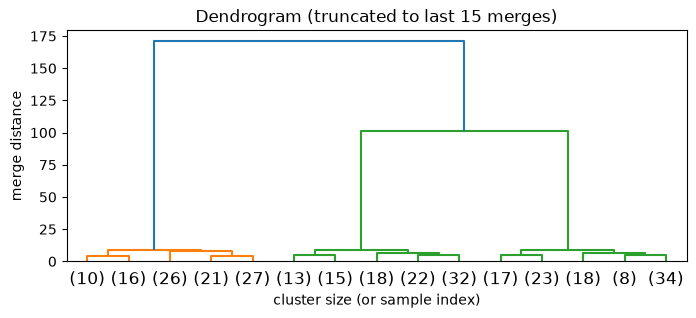

agglomerative clustering ARI: 1.000


In [4]:
Z = linkage(X_blobs, method="ward")

fig, ax = plt.subplots(figsize=(8, 3))
dendrogram(Z, truncate_mode="lastp", p=15, ax=ax)
ax.set_title("Dendrogram (truncated to last 15 merges)")
ax.set_xlabel("cluster size (or sample index)"); ax.set_ylabel("merge distance")
plt.show()

agglo = AgglomerativeClustering(n_clusters=3).fit(X_blobs)
ari_agglo = adjusted_rand_score(y_true_blobs, agglo.labels_)
print(f"agglomerative clustering ARI: {ari_agglo:.3f}")
assert ari_agglo > 0.8


## 4. Where K-means fails: non-convex clusters

⚠️ **Common Mistake:** assuming K-means "just works" for any clustering problem. K-means
assigns points to the *nearest centroid*, which only matches the true groups when clusters are
roughly convex/spherical.

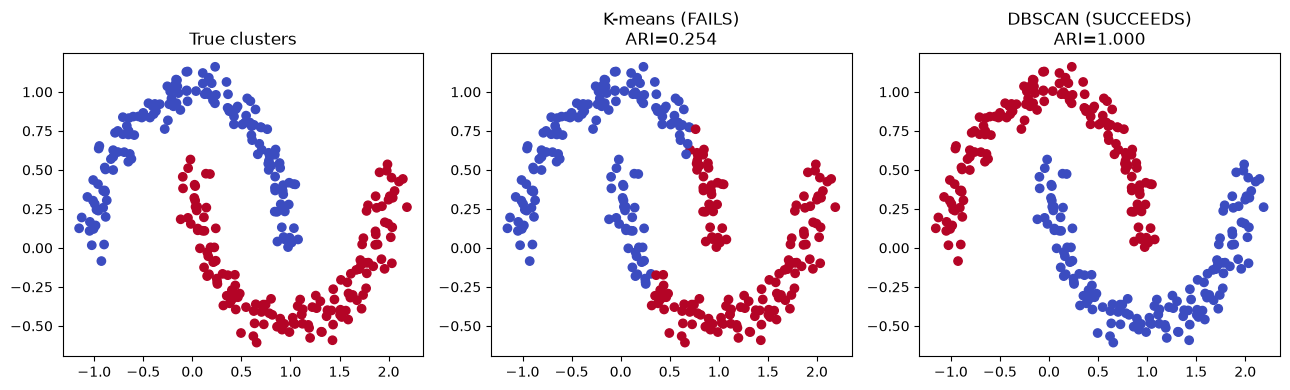

K-means ARI on moons: 0.254 (poor -- centroid distance can't follow the curve)
DBSCAN ARI on moons:  1.000 (good -- density-based, follows the curved shape)


In [5]:
X_moons, y_true_moons = make_moons(n_samples=300, noise=0.07, random_state=42)

kmeans_moons = KMeans(n_clusters=2, random_state=42, n_init=10).fit(X_moons)
dbscan_moons = DBSCAN(eps=0.2, min_samples=5).fit(X_moons)

fig, axes = plt.subplots(1, 3, figsize=(13, 4))
axes[0].scatter(X_moons[:, 0], X_moons[:, 1], c=y_true_moons, cmap="coolwarm")
axes[0].set_title("True clusters")
axes[1].scatter(X_moons[:, 0], X_moons[:, 1], c=kmeans_moons.labels_, cmap="coolwarm")
axes[1].set_title(f"K-means (FAILS)\nARI={adjusted_rand_score(y_true_moons, kmeans_moons.labels_):.3f}")
axes[2].scatter(X_moons[:, 0], X_moons[:, 1], c=dbscan_moons.labels_, cmap="coolwarm")
axes[2].set_title(f"DBSCAN (SUCCEEDS)\nARI={adjusted_rand_score(y_true_moons, dbscan_moons.labels_):.3f}")
plt.tight_layout(); plt.show()

kmeans_ari = adjusted_rand_score(y_true_moons, kmeans_moons.labels_)
dbscan_ari = adjusted_rand_score(y_true_moons, dbscan_moons.labels_)
print(f"K-means ARI on moons: {kmeans_ari:.3f} (poor -- centroid distance can't follow the curve)")
print(f"DBSCAN ARI on moons:  {dbscan_ari:.3f} (good -- density-based, follows the curved shape)")

assert dbscan_ari > kmeans_ari
assert dbscan_ari > 0.8


## 5. DBSCAN and noise/outlier detection

💡 **Key Idea:** DBSCAN labels sparse points `-1` (noise) instead of forcing every point into a
cluster — useful for outlier/anomaly detection as a side effect of clustering.

In [6]:
X_with_outliers = np.vstack([X_blobs, rng.uniform(-10, 10, size=(10, 2))])  # inject 10 outliers
dbscan_outliers = DBSCAN(eps=0.9, min_samples=5).fit(X_with_outliers)

n_noise = (dbscan_outliers.labels_ == -1).sum()
print(f"points labeled as noise (-1): {n_noise} / {len(X_with_outliers)}")
print("Most of the 10 injected outliers should be caught as noise.")
assert n_noise >= 5


points labeled as noise (-1): 11 / 310
Most of the 10 injected outliers should be caught as noise.


## 6. Connection to what's next

Both K-means and DBSCAN are distance-based and were applied here on 2D data for visualization.
`02_dimensionality_reduction.ipynb` shows how to get real, higher-dimensional data down to 2D
first (via PCA or t-SNE) so the same visual intuition applies.

## 7. Interview questions
1. Why does K-means fail on the two-moons dataset but succeed on well-separated blobs?
2. What do the two DBSCAN hyperparameters (`eps`, `min_samples`) control?
3. How does the elbow method help choose `k`, and what's its main limitation?
4. What does a dendrogram's merge height represent?
5. Why might DBSCAN be preferred for anomaly detection specifically?

## 8. Exercises
1. Vary DBSCAN's `eps` from 0.05 to 0.5 on the moons dataset and observe how the clustering changes.
2. Cut the dendrogram at a different height to produce 2 clusters instead of 3, and compare to the true blob labels.
3. Run K-means with `k=2` and `k=5` on the blob data (true k=3) and discuss what goes wrong in each case.

## 9. Summary

✅ K-means assumes spherical clusters and needs `k` chosen upfront; hierarchical clustering
shows structure at every granularity via a dendrogram; DBSCAN follows density and naturally
finds outliers. Next: `02_dimensionality_reduction.ipynb`.